# Assignment 5: Exploratory Data Analysis of SDVOSB Goaling Achievement

**Research question:** Is greater distance below the new 5% benchmark before FY2024 associated with larger subsequent changes in SBA-reported SDVOSB achievement?

This notebook imports the reusable `sdvosb_federal_analytics.eda` module. It describes associations, not causal policy effects. The 24 scored agencies are the independent units for cross-sectional comparisons. FY2025 USAID achievement is source-declared missing and is not converted to zero.

## 1. Reconstruct the A4 and A5 data foundations

From a clean checkout, run the commands in the root `README.md` to build the A4 SQLite database and supplementary `analysis.sqlite` before executing this notebook. No downloaded live files are needed: the source is the frozen FY2021–FY2025 SBA JSON and FY2020 legacy PDFs.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

repo = Path.cwd()
if not (repo / 'pyproject.toml').exists() and (repo.parent / 'pyproject.toml').exists():
    repo = repo.parent
if not (repo / 'pyproject.toml').exists():
    raise FileNotFoundError('Open this notebook from the project root or notebooks/ folder')
sys.path.insert(0, str(repo / 'src'))
from sdvosb_federal_analytics.eda import (load_tables, agency_changes,
    describe_variables, welch_analysis, run_regressions, correlation_matrix, run_eda)

panel, history, vendors = load_tables(repo/'data/processed/scorecards.sqlite',
                                     repo/'data/processed/analysis.sqlite')
changes = agency_changes(panel)
print(f'{len(panel)} agency-years; {len(changes)} agencies; '
      f'{panel.achievement_pct.notna().sum()} complete achievement rows')

144 agency-years; 24 agencies; 143 complete achievement rows


## 2. Univariate distributions and missingness

The first figure shows **all 24 agencies**, including the 12 agencies with zero measured baseline shortfall. The baseline is FY2021–FY2023. Numerical values are the percentages displayed by SBA rather than unadjusted award shares.

In [2]:
descriptives = describe_variables(panel, history, changes)
display(descriptives)
display(changes[['agency_id','baseline_average_pct','shortfall_pp']].sort_values('shortfall_pp',ascending=False))

,variable,source_field,units,dtype,total_rows,nonmissing,missing,min,q25,median,mean,q75,max
0,SBA goaling achievement,achievement_pct,percentage points,float64,144,143,1,-5.040000,2.825000,5.060000,7.071608,7.885000,60.130000
1,Agency scorecard goal,goal_pct,percent,float64,144,143,1,3.000000,3.000000,3.000000,3.657343,5.000000,5.000000
2,SBA-reported SDVOSB dollars,sdvosb_dollars_millions,USD millions,float64,144,143,1,-50.600000,63.900000,316.100000,1208.849650,706.350000,12100.000000
3,FY2021–2023 baseline,baseline_average_pct,percentage points,float64,24,24,0,0.463333,2.674167,5.046667,6.948194,7.168333,36.533333
4,Distance below 5%,shortfall_pp,percentage points,float64,24,24,0,0.000000,0.000000,0.138333,1.134167,2.325833,4.536667
5,SDVOSB prime contractor count,sdvosb_prime_contractor_count,contractors,float64,144,143,1,18.000000,37.000000,127.000000,387.790210,347.000000,3319.000000
6,SDVOSB/all small-business contractor ratio,sdvosb_to_small_business_ratio,proportion,float64,144,143,1,0.043254,0.076250,0.097120,0.112206,0.128743,0.298846
7,Historical achievement FY2017–2025,achievement_pct,percentage points,float64,216,215,1,-5.040000,2.770000,4.520000,6.411349,6.880000,60.130000


,agency_id,baseline_average_pct,shortfall_pp
21,USAID,0.463333,4.536667
9,ED,1.463333,3.536667
14,NASA,1.796667,3.203333
3,DOE,2.033333,2.966667
12,HHS,2.040000,2.960000
10,EPA,2.596667,2.403333
13,HUD,2.700000,2.300000
2,DOD,3.080000,1.920000
20,TREAS,3.896667,1.103333
7,DOS,3.903333,1.096667


## 3. Bivariate changes, the documented exploratory Welch comparison, and assumptions

H0: equal mean FY2023-to-FY2024 changes between the two shortfall groups. H1 for the two-sided test: their mean changes differ. The separate scientific directional prediction is a larger positive change in agencies whose FY2021–FY2023 average is below 5%. The A5 test was documented after an initial feasibility run, not blindly preregistered. The primary test is a **two-sided Welch comparison**; its 95% interval, Hedges' g, group-specific Shapiro checks, Mann–Whitney sensitivity, and Spearman correlation are reported. Diagnostic normality tests do **not** determine which inferential test is selected.

In [3]:
summary_2024 = welch_analysis(changes,2024)
summary_2025 = welch_analysis(changes,2025)
display(pd.DataFrame([summary_2024, summary_2025]).T)

,0,1
year,2024.000000,2025.000000
n_total,24.000000,23.000000
n_positive,12.000000,11.000000
n_zero,12.000000,12.000000
mean_positive,0.415000,0.860000
mean_zero,0.044167,-0.295000
difference,0.370833,1.155000
standard_error,0.787757,1.748258
welch_df,15.651844,12.921201
welch_t,0.470746,0.660658


**Interpretation boundary:** FY2023 is included in the baseline exposure average and subtracted in the change outcome. This mechanically couples the quantities. Group tests and correlations are descriptive checks; they cannot establish a policy response. FY2024 and FY2025 are analyzed separately.

## 4. Multivariate exploration and influential observations

A simple OLS change-on-shortfall model is saved as a later comparison for A6. A separate descriptive HC3 regression adds log FY2023 SDVOSB contracting dollars, with Cook's distance used to identify influential observations. None of these estimates is claimed as causal.

In [4]:
models, influential, influence_summary = run_regressions(changes)
display(models)
display(influential.head(8))
correlations = correlation_matrix(changes)
display(correlations)

,model,variable,coefficient,se_hc3,p_value,ci_low,ci_high,r_squared,nobs
0,simple_OLS_HC3,Intercept,0.213219,0.625762,0.736535,-1.084532,1.510971,0.000121,24
1,simple_OLS_HC3,shortfall_pp,0.014428,0.214462,0.946969,-0.430339,0.459195,0.000121,24
2,multivariable_OLS_HC3,Intercept,1.014899,1.578941,0.527329,-2.268689,4.298486,0.014977,24
3,multivariable_OLS_HC3,shortfall_pp,-0.013493,0.221373,0.951974,-0.473862,0.446876,0.014977,24
4,multivariable_OLS_HC3,log_fy2023_dollars,-0.134477,0.265660,0.617991,-0.686947,0.417993,0.014977,24


,agency_id,cooks_distance,leverage,residual,threshold_4_over_n
23,VA,0.356702,0.227459,-3.301050,0.166667
18,SBA,0.185667,0.072463,5.066044,0.166667
15,NRC,0.145246,0.257161,-1.904906,0.166667
11,GSA,0.120727,0.076299,-3.964637,0.166667
20,TREAS,0.053940,0.043268,3.644956,0.166667
19,SSA,0.028409,0.069594,2.028353,0.166667
17,OPM,0.023481,0.116200,-1.355627,0.166667
9,ED,0.023462,0.200543,-0.933056,0.166667


,baseline_average_pct,shortfall_pp,delta_2024,delta_2025,log_fy2023_dollars,sdvosb_contractors_2023
baseline_average_pct,1.000000,-0.935763,-0.048696,-0.310277,0.136522,0.185258
shortfall_pp,-0.935763,1.000000,-0.009757,0.360426,-0.054362,-0.184033
delta_2024,-0.048696,-0.009757,1.000000,0.534585,-0.039130,0.026093
delta_2025,-0.310277,0.360426,0.534585,1.000000,0.051383,-0.032123
log_fy2023_dollars,0.136522,-0.054362,-0.039130,0.051383,1.000000,0.862796
sdvosb_contractors_2023,0.185258,-0.184033,0.026093,-0.032123,0.862796,1.000000


## 5. Publication-oriented figures and machine-readable outputs

All figures are created from reusable module functions. `run_eda` writes results for A6 and the subsequent dashboard; no values are manually hard-coded.

Saved 10 figures and result tables


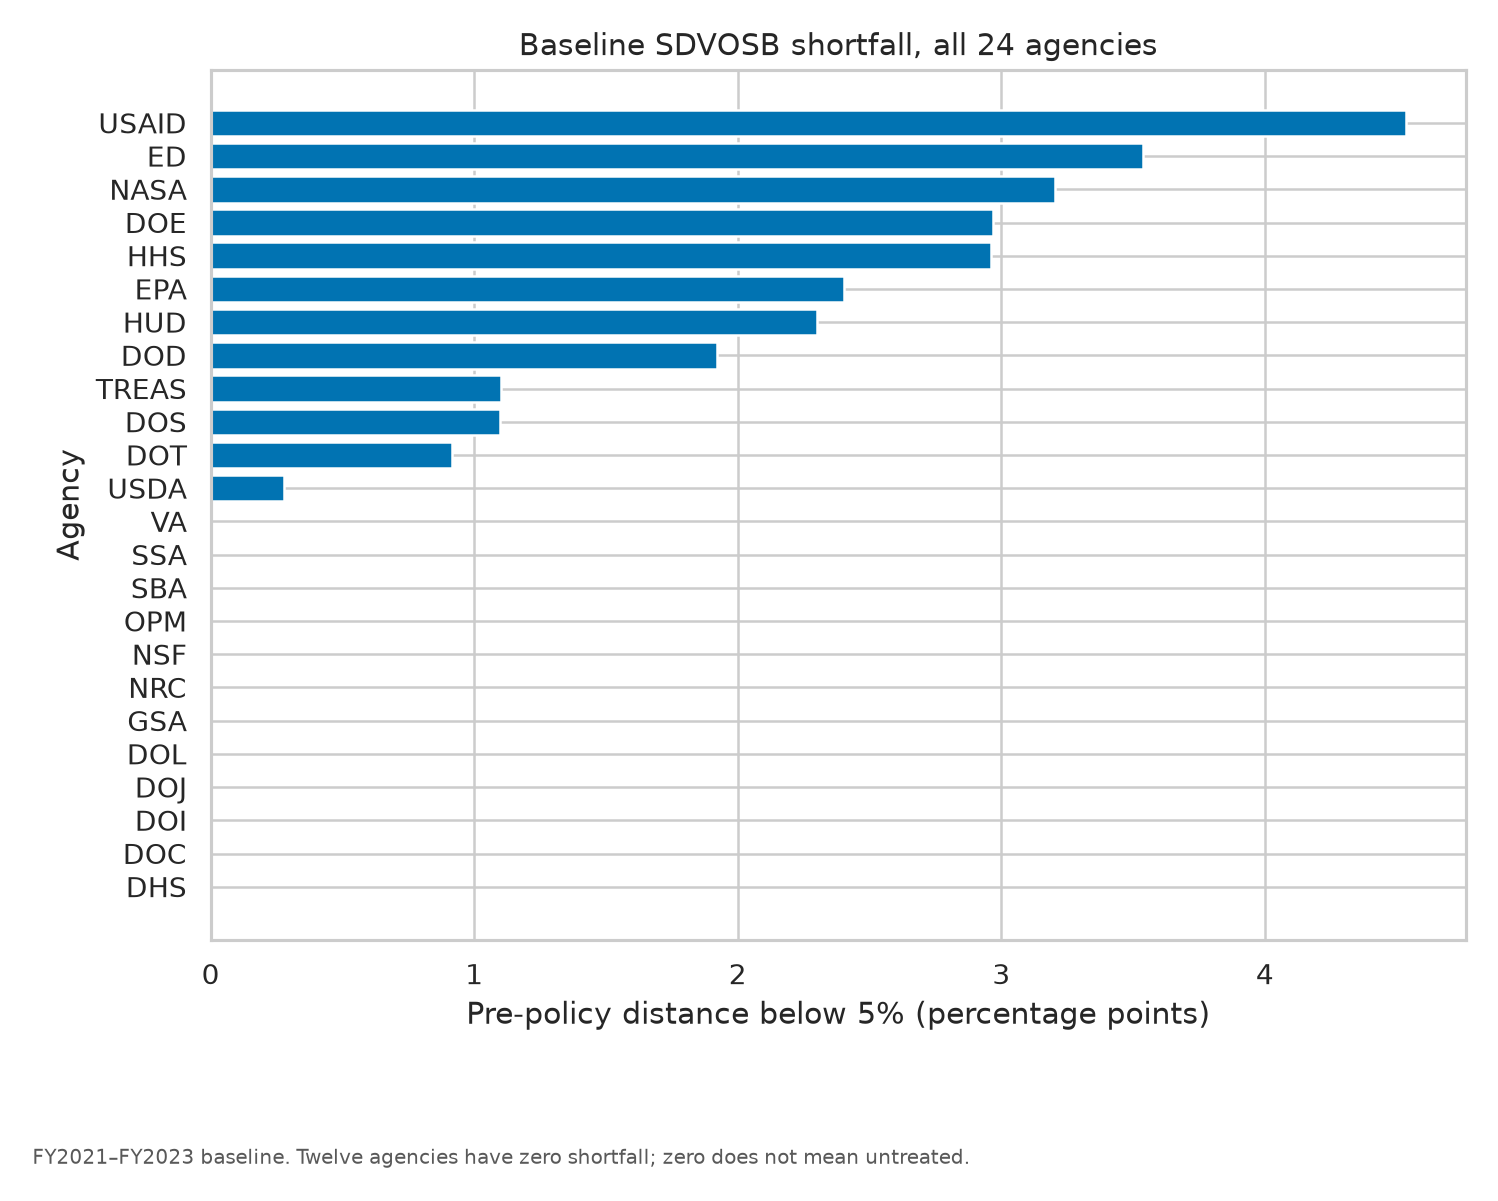

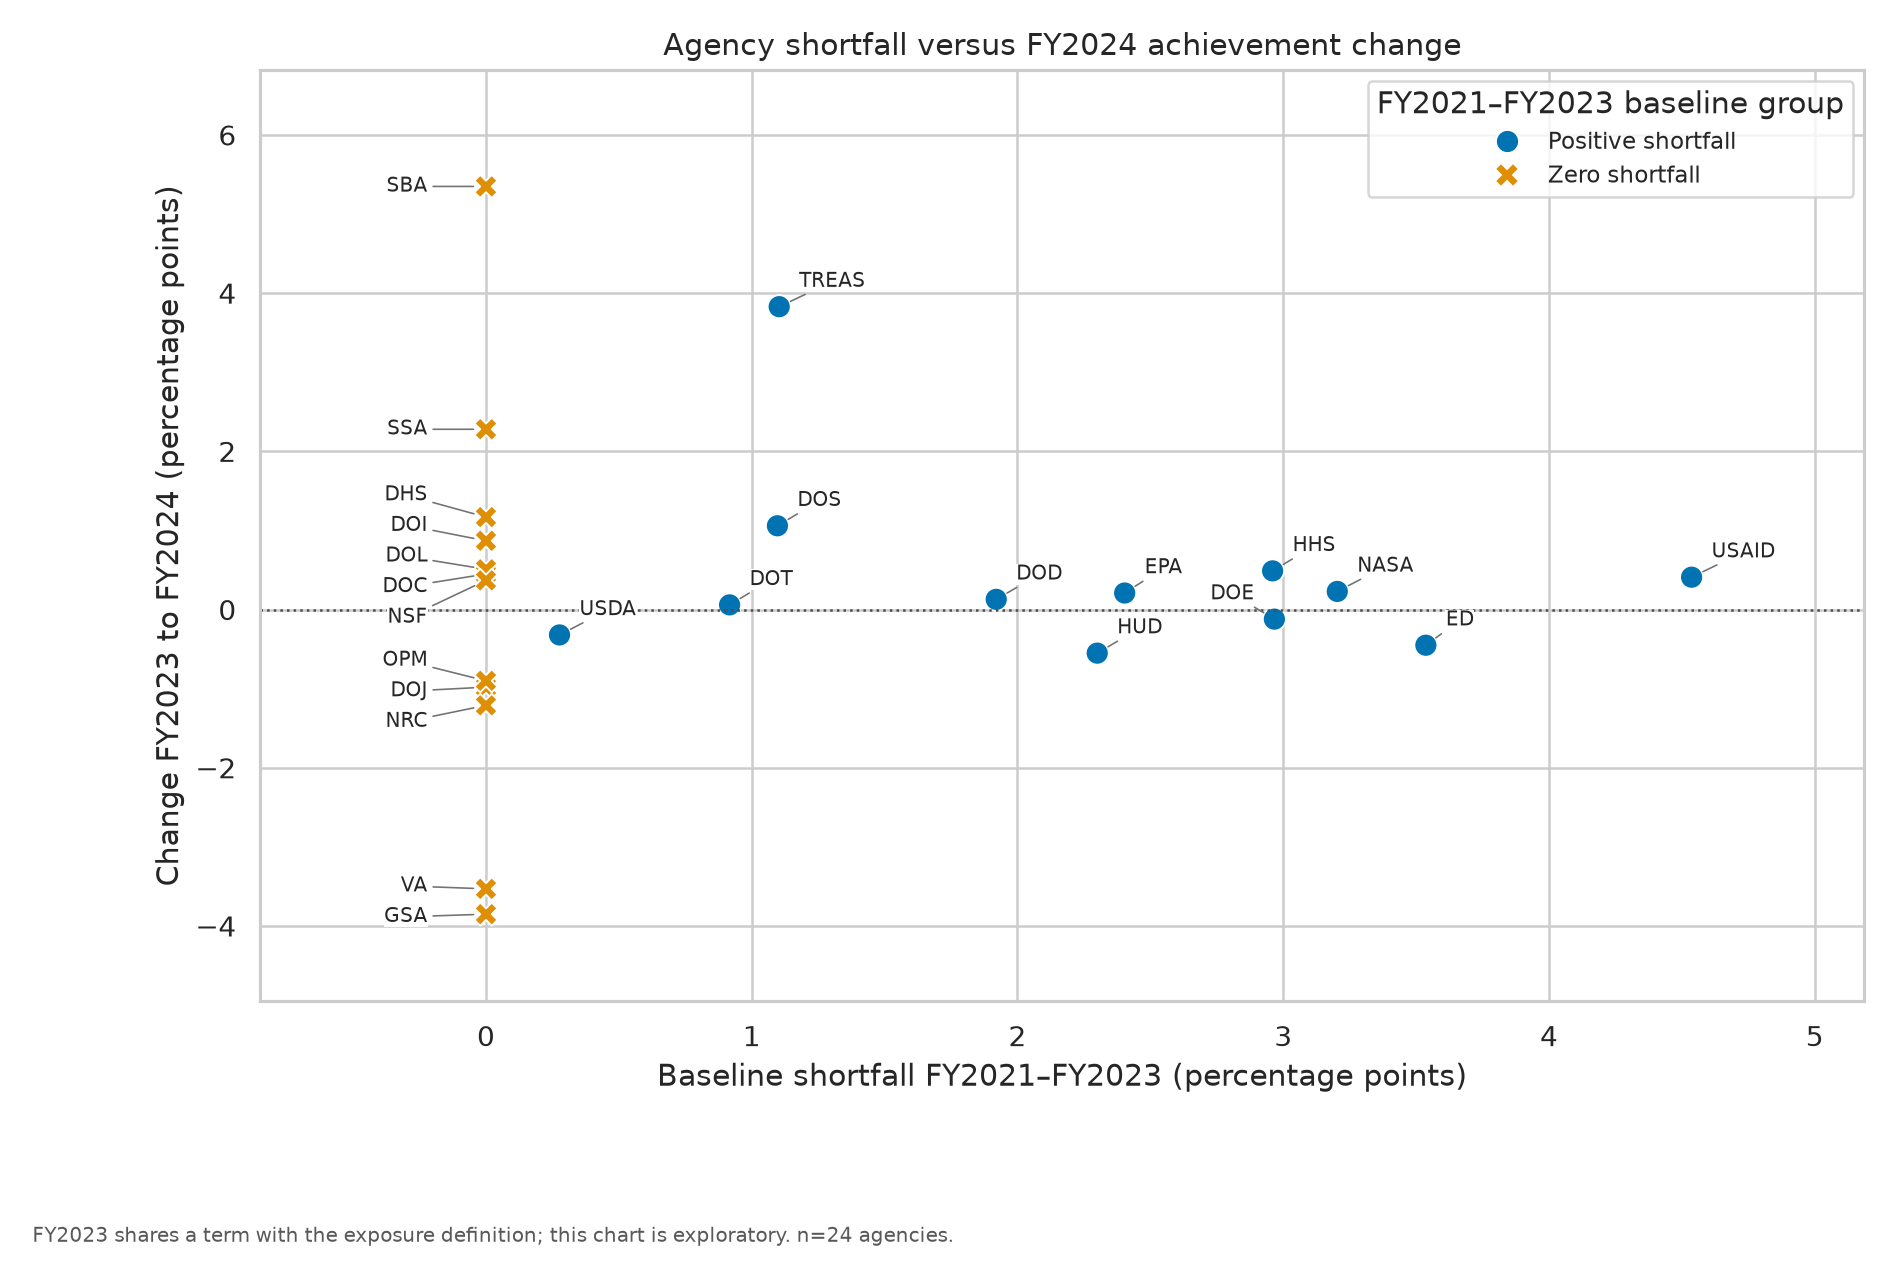

In [5]:
report=run_eda(repo/'data/processed/scorecards.sqlite',
               repo/'data/processed/analysis.sqlite',repo/'results',repo/'figures')
print('Saved', len(report['saved_figures']), 'figures and result tables')
display(Image(filename=str(repo/'figures/a5_01_shortfall_distribution.png'),width=740))
display(Image(filename=str(repo/'figures/a5_04_shortfall_vs_change_2024.png'),width=740))

## 6. Business interpretation and limitations

The FY2024 shortfall-group mean-change difference is small and statistically inconclusive. The FY2025 comparison is also inconclusive. The exploratory cross-sectional patterns do not establish a causal effect of the federal goal change. Source comparability, FY2022 deobligation accounting, DOE M&O inclusion, VA denominator questions, certification changes in FY2025, and sample size (24 agencies) remain explicit limitations. SDVOSB firms should match actual procurement opportunities to their capabilities rather than assume a lagging agency will catch up. Agency staff should reconcile reporting definitions before interpreting year-to-year changes. The appropriate next research step is A6's model comparison and sensitivity analysis.

The source trace, execution ownership, and author-review status are documented in `docs/A5_CORRECTION_REPORT.md`, `docs/AI_USE.md`, and `docs/REVIEW_CHECKLIST.md`. A computational check is not a claim that the author personally performed it.